# 08 · Selected reserve, and how it turned out

**Question this notebook answers:** what reserve would I recommend for Penn National at 31/12/1997, how did I get there year by year, and how close was it?

The selection is made **first**, using only information available at the valuation date plus the cross-company evidence from notebook 06. Hindsight comes in section 6, after the selection is fixed.

### The evidence so far

| Source | Finding | Implication |
|---|---|---|
| Notebook 02: paid/case ratios | rose ~3-6% along diagonals from 1993 | paid CL may overstate (faster settlement) **or** case CL may understate (weaker case reserves); can't tell without counts |
| Notebook 02: residuals | no calendar-year trend | no explicit inflation adjustment |
| Notebook 02/04: loss ratios | company has drifted well above industry since 1994 | prior from company's own data (Gen. Cape Cod), not the industry |
| Notebook 03: factors | basis matters far more than averaging rule | all-year volume-weighted; the paid/case question is settled at selection |
| Notebook 04: leverage | 1997 paid CDF ≈ 4.8 | avoid paid CL for immature years |
| Notebook 05: uncertainty | paid and case bootstraps barely overlap | model risk > statistical risk |
| Notebook 06: back-test (30 companies) | case/Cape Cod best when immature; paid best when mature; opposite biases | maturity-weighted blend, which beats every single method out of sample |

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from reserving import config as cfg, data as D, plots as PL

PL.setup()
pd.options.display.float_format = "{:,.3f}".format
pd.options.display.width = 140

In [2]:
from reserving.pipeline import run
from reserving.selection import band_of
from reserving import backtest as B

rev = run()
co, sel = rev.co, rev.selected
methods = cfg.SELECTION_METHODS

## 1. From evidence weights to selected weights

Start from the inverse-MSE weights learned on the other 30 companies (notebook 06), then apply one company-specific adjustment:

> **Paid weight halved for ages 1-5.** The company's paid/case ratio has shifted upward since 1993. If that's faster settlement, every paid-based method on recent years overstates, and the industry evidence can't know about this company-specific shift. The freed weight goes to the case-based methods in proportion. Mature years (6-10) are unaffected because they're almost fully paid and the paid pattern there is long established.

In [3]:
w = pd.concat({"evidence (30 other companies)": rev.weights_evidence, "selected (after adjustment)": rev.weights_selected}, axis=1)
w.style.format("{:.0%}")

Why this adjustment and not another? It's the minimum change that responds to the one company-specific risk the evidence can't see. An alternative would be to also reduce the case weight in case case reserves had weakened, but the cross-company bias (case methods already run ~1-2% light) is already priced into the evidence weights. The sensitivity in section 4 shows what happens without the adjustment.

## 2. Selected reserve by accident year

In [4]:
ult = rev.ultimates[methods]
tbl = pd.DataFrame({
    "age": sel["age"],
    "band": sel["band"],
    **{f"{m}": ult[m] - sel["paid"] for m in methods},
    "selected unpaid": sel["selected_unpaid"],
    "of which IBNR": sel["selected_ibnr"],
    "selected LR": sel["selected_lr"],
})
tot = tbl.sum(numeric_only=True)
tot["age"] = np.nan
tot["selected LR"] = sel["selected_ultimate"].sum() / sel["premium"].sum()
tbl.loc["Total"] = tot
tbl.loc["Total", "band"] = ""
tbl.style.format({c: "{:,.0f}" for c in methods + ["selected unpaid", "of which IBNR"]} | {"selected LR": "{:.1%}", "age": "{:.0f}"}, na_rep="")

,age,band,CL paid,CL case,Cape Cod paid,Gen. Cape Cod case,selected unpaid,of which IBNR,selected LR
1988,10,6-10 (mature),137,174,160,179,157,38,64.4%
1989,9,6-10 (mature),154,243,151,238,179,4,76.3%
1990,8,6-10 (mature),329,150,342,149,279,192,71.9%
1991,7,6-10 (mature),546,911,714,952,720,9,57.8%
1992,6,6-10 (mature),"1,526",724,"1,777",763,"1,373",929,64.1%
1993,5,3-5 (developing),"3,455","2,681","3,544","2,693","2,859",675,72.0%
1994,4,3-5 (developing),"9,287","6,442","8,052","6,298","6,842","2,334",82.2%
1995,3,3-5 (developing),"16,678","12,492","13,924","12,215","12,947","4,803",83.1%
1996,2,1-2 (immature),"23,895","18,781","18,511","18,025","18,735","8,134",85.9%
1997,1,1-2 (immature),"34,081","26,637","25,134","25,531","26,431","16,115",83.7%


### Rationale by year

| Years | Maturity | What drives the selection | Why |
|---|---|---|---|
| **1988-1992** | 6-10 years, ≥ 90% paid | ~70% paid methods | almost fully developed; paid is "hard" cash with a stable, long history; the back-test shows paid most accurate at these ages. All methods agree within $1m in total anyway. |
| **1993-1995** | 3-5 years | ~80% case methods (CL case + Gen. Cape Cod) | case incurred is 90-99% reported, so it carries more information than paid (66-91%); paid weight cut because of the paid/case shift |
| **1996-1997** | 1-2 years | ~80% case methods, ~45% weight on Gen. Cape Cod | thin data, huge paid CDFs (2.1 and 4.8); the prior-driven Cape Cod stabilises the estimate; back-test shows it as the best single method at these ages |

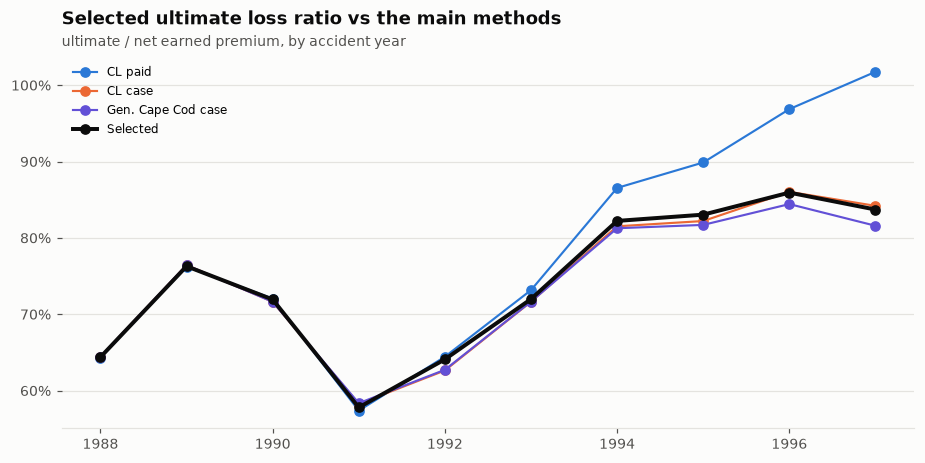

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.4))
yrs = sel.index
ax.plot(yrs, rev.ultimates["CL paid"] / co.premium, color=PL.COLOURS["CL paid"], marker="o", lw=1.4, label="CL paid")
ax.plot(yrs, rev.ultimates["CL case"] / co.premium, color=PL.COLOURS["CL case"], marker="o", lw=1.4, label="CL case")
ax.plot(yrs, rev.ultimates["Gen. Cape Cod case"] / co.premium, color=PL.COLOURS["Gen. Cape Cod case"], marker="o", lw=1.4, label="Gen. Cape Cod case")
ax.plot(yrs, sel["selected_lr"], color=PL.INK, marker="o", lw=2.6, label="Selected")
ax.set_title("Selected ultimate loss ratio vs the main methods")
PL.subtitle(ax, "ultimate / net earned premium, by accident year")
PL.pct(ax)
ax.legend(fontsize=8, loc="upper left")
PL.save(fig, "08_selected_lr")
plt.show()

## 3. Reasonableness checks

A selected reserve should make sense from several angles, not only the methods that produced it.

In [6]:
case_os = sel["case_incurred"] - sel["paid"]
checks = pd.DataFrame({
    "selected LR": sel["selected_lr"],
    "Gen. Cape Cod prior LR": rev.results["Gen. Cape Cod case"]["elr"],
    "% paid of selected ult": sel["paid"] / sel["selected_ultimate"],
    "paid pattern (1/CDF)": 1 / rev.cdf_paid.reindex(sel["age"]).values,
    "% case-reported of selected ult": sel["case_incurred"] / sel["selected_ultimate"],
    "case pattern (1/CDF)": 1 / rev.cdf_case.reindex(sel["age"]).values,
    "IBNR / case O/S": sel["selected_ibnr"] / case_os,
})
checks.style.format("{:.1%}")

,selected LR,Gen. Cape Cod prior LR,% paid of selected ult,paid pattern (1/CDF),% case-reported of selected ult,case pattern (1/CDF),IBNR / case O/S
1988,64.4%,69.9%,99.4%,99.5%,99.9%,99.8%,31.8%
1989,76.3%,70.6%,99.4%,99.5%,100.0%,99.8%,2.3%
1990,71.9%,70.5%,99.1%,98.9%,99.4%,99.8%,220.7%
1991,57.8%,70.3%,97.0%,97.7%,100.0%,99.2%,1.2%
1992,64.1%,71.3%,95.2%,94.7%,96.7%,99.0%,209.3%
1993,72.0%,73.3%,92.2%,90.7%,98.2%,98.6%,30.9%
1994,82.2%,75.5%,85.3%,81.0%,95.0%,95.8%,51.8%
1995,83.1%,77.0%,71.5%,66.0%,89.4%,90.3%,59.0%
1996,85.9%,78.1%,53.8%,47.7%,79.9%,79.9%,76.7%
1997,83.7%,78.5%,25.6%,21.0%,54.6%,54.3%,156.2%


* **Loss ratios:** selected 1994-97 loss ratios of 82-86% sit close to the case chain ladder and above the Cape Cod prior (75-79%), following the company's upward drift without any year jumping on thin data (unlike paid CL's 102% for 1997). The 1991 dip (~58%) is in every method; it's a genuinely good year, not a projection artefact.
* **Implied development:** for recent years the paid-to-date share of the selected ultimate is *above* the historical paid pattern. That's consistent with faster settlement, and it's the paid/case shift again, now visible in the selection.
* **IBNR vs case reserves:** for 1997, IBNR is 1.6× the case reserves, as expected for a year with only 12 months of reporting. For mature years both amounts are tiny, so the ratio is erratic and not meaningful.

### Comparison with the company's posted reserve

In [7]:
posted = rev.extras["posted_reserve_97"]
selected_total = sel["selected_unpaid"].sum()
pd.Series({
    "Selected unpaid (this review)": selected_total,
    "Company posted reserve at 31/12/1997 (Schedule P)": posted,
    "Difference": posted - selected_total,
    "Difference as % of selected": posted / selected_total - 1,
}).to_frame("USD 000").style.format("{:,.0f}", subset=pd.IndexSlice[["Selected unpaid (this review)", "Company posted reserve at 31/12/1997 (Schedule P)", "Difference"], :]).format("{:+.1%}", subset=pd.IndexSlice[["Difference as % of selected"], :])

,USD 000
Selected unpaid (this review),"70,522"
Company posted reserve at 31/12/1997 (Schedule P),"75,716"
Difference,"5,194"
Difference as % of selected,+7.4%


The company held about **7% more** than my selected best estimate. That's typical: booked reserves usually include a **margin for prudence** above the actuarial central estimate, and in 1997 the US statutory regime had no explicit risk margin, so prudence sat implicitly in the booked figure. This difference would be discussed with management, not "corrected". The company's margin sits around the **75th-80th percentile** of my range below.

## 4. Range and sensitivities

In [8]:
p = rev.extras["selected_percentiles"]
rng = pd.Series({"25th percentile": p[0.25], "Selected (mean)": selected_total, "75th percentile": p[0.75],
                 "95th percentile": p[0.95], "99.5th percentile": p[0.995]})
print(f"CV used: {rev.extras['selected_cv']:.1%} (Mack, case incurred basis), lognormal")
rng.to_frame("USD 000").style.format("{:,.0f}")

CV used: 8.7% (Mack, case incurred basis), lognormal


,USD 000
25th percentile,"66,279"
Selected (mean),"70,522"
75th percentile,"74,478"
95th percentile,"80,995"
99.5th percentile,"87,784"


In [9]:
from reserving.selection import band_weights, blend
from reserving.factors import average_factors, cdfs
from reserving.methods import chain_ladder, cape_cod
paid_latest = sel["paid"]
ages = sel["age"]

def blended_total(ult_df, weights):
    return float((blend(ult_df, ages, weights) - paid_latest).sum())

sens = {"Selected": selected_total}
sens["No paid haircut (pure evidence weights)"] = blended_total(rev.ultimates, rev.weights_evidence)
alt = rev.ultimates.copy()
f5p, f5c = cdfs(average_factors(co.paid, n_periods=5), cfg.TAIL_PAID), cdfs(average_factors(co.case, n_periods=5), cfg.TAIL_CASE)
alt["CL paid"] = chain_ladder(co.paid, f5p)["ultimate"]; alt["CL case"] = chain_ladder(co.case, f5c)["ultimate"]
alt["Cape Cod paid"] = cape_cod(co.paid, f5p, co.premium)["ultimate"]; alt["Gen. Cape Cod case"] = cape_cod(co.case, f5c, co.premium, decay=cfg.CAPE_COD_DECAY)["ultimate"]
sens["5-year factors instead of all-year"] = blended_total(alt, rev.weights_selected)
alt2 = rev.ultimates.copy(); alt2["Gen. Cape Cod case"] = rev.ultimates["BF case"]
sens["Industry prior instead of Gen. Cape Cod"] = blended_total(alt2, rev.weights_selected)
alt3 = rev.ultimates.copy()
alt3["CL paid"] = chain_ladder(co.paid, cdfs(average_factors(co.paid), 1.015))["ultimate"]
alt3["CL case"] = chain_ladder(co.case, cdfs(average_factors(co.case), 1.012))["ultimate"]
sens["Tails +1% on both bases (CL only)"] = blended_total(alt3, rev.weights_selected)
sens["Case methods only (CL case + Gen. CC, evidence split)"] = blended_total(rev.ultimates, rev.weights_selected.assign(**{"CL paid": 0, "Cape Cod paid": 0}).pipe(lambda d: d.div(d.sum(axis=1), axis=0)))
s = pd.Series(sens).to_frame("total unpaid")
s["vs selected"] = s["total unpaid"] / selected_total - 1
s.style.format({"total unpaid": "{:,.0f}", "vs selected": "{:+.1%}"})

,total unpaid,vs selected
Selected,"70,522",+0.0%
No paid haircut (pure evidence weights),"72,545",+2.9%
5-year factors instead of all-year,"72,847",+3.3%
Industry prior instead of Gen. Cape Cod,"68,179",-3.3%
Tails +1% on both bases (CL only),"72,182",+2.4%
"Case methods only (CL case + Gen. CC, evidence split)","68,037",-3.5%


The selection is robust: every reasonable alternative judgement moves it by only ±2-4%, all inside the interquartile range. The full spread across *methods* ($61-90m) is much wider than across *reasonable selections*, which shows the value of the structured approach.

### Recommendation

> **Selected best-estimate unpaid claims for Penn National commercial auto at 31/12/1997: about $70.5m (net), of which $33.2m is IBNR above case reserves.**
> Reasonable range (interquartile) **$66m-$74m**. The 95th percentile is about **$81m**, although stochastic ranges understate model risk here (notebook 05).
> The main uncertainty is whether the post-1993 rise in paid-to-case ratios reflects faster settlement or weaker case reserves. **Recommended next step: obtain claim counts (reported, closed, open) to run Berquist-Sherman diagnostics**, as demonstrated on claim-level data in notebook 07.

## 5. Hindsight: how did it turn out?

Now the lower triangle, never used above. "Actual" = reported incurred after 10 years of development.

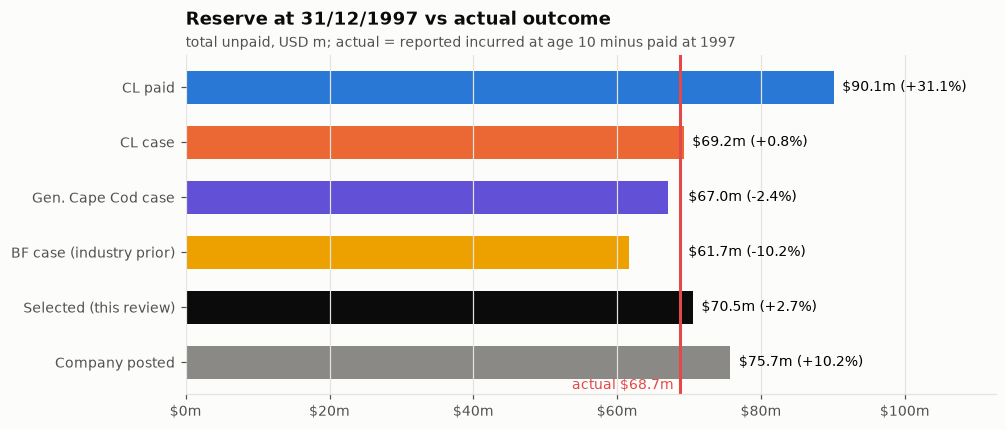

,total unpaid,error vs actual
CL paid,"90,088",+31.1%
CL case,"69,235",+0.8%
Gen. Cape Cod case,"67,042",-2.4%
BF case (industry prior),"61,699",-10.2%
Selected (this review),"70,522",+2.7%
Company posted,"75,716",+10.2%
Actual (hindsight),"68,691",+0.0%


In [10]:
actual = sel["actual_unpaid_hindsight"]
compare = pd.DataFrame({
    "CL paid": rev.unpaid["CL paid"].sum(),
    "CL case": rev.unpaid["CL case"].sum(),
    "Gen. Cape Cod case": rev.unpaid["Gen. Cape Cod case"].sum(),
    "BF case (industry prior)": rev.unpaid["BF case"].sum(),
    "Selected (this review)": selected_total,
    "Company posted": posted,
    "Actual (hindsight)": actual.sum(),
}, index=["total unpaid"]).T
compare["error vs actual"] = compare["total unpaid"] / actual.sum() - 1

fig, ax = plt.subplots(figsize=(9.5, 4))
labels = compare.index[:-1]
cols = [PL.COLOURS["CL paid"], PL.COLOURS["CL case"], PL.COLOURS["Gen. Cape Cod case"], PL.COLOURS["BF case"], PL.INK, PL.NEUTRAL]
ax.barh(range(len(labels)), compare["total unpaid"].iloc[:-1] / 1e3, color=cols, height=0.6)
ax.axvline(actual.sum() / 1e3, color=PL.SERIES[7], lw=2)
ax.text(actual.sum() / 1e3 - 0.8, len(labels) - 0.45, f"actual ${actual.sum()/1e3:,.1f}m", color=PL.SERIES[7], fontsize=9, ha="right", va="bottom")
xmax_lab = actual.sum() / 1e3
for i, (v, e) in enumerate(zip(compare["total unpaid"].iloc[:-1], compare["error vs actual"].iloc[:-1])):
    ax.text(max(v / 1e3, xmax_lab) + 1.2, i, f"${v/1e3:,.1f}m ({e:+.1%})", va="center", fontsize=9)
ax.set_yticks(range(len(labels)), labels)
ax.invert_yaxis(); ax.grid(True, axis="x"); ax.grid(False, axis="y")
ax.set_xlim(0, compare["total unpaid"].max() / 1e3 * 1.25)
PL.money(ax, axis="x", unit="m", prefix="$")
ax.set_title("Reserve at 31/12/1997 vs actual outcome")
PL.subtitle(ax, "total unpaid, USD m; actual = reported incurred at age 10 minus paid at 1997")
PL.save(fig, "08_hindsight_totals")
plt.show()
compare.style.format({"total unpaid": "{:,.0f}", "error vs actual": "{:+.1%}"})

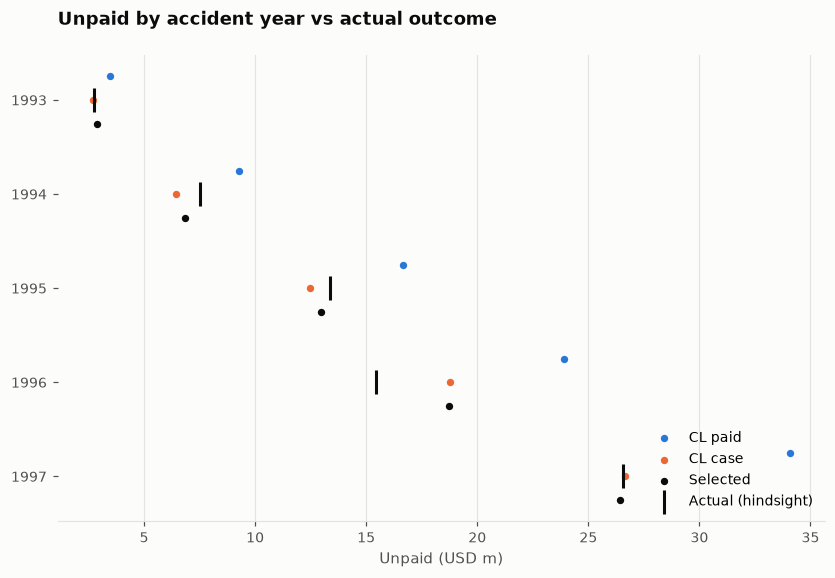

,CL paid,CL case,Selected,Actual
1993,3.5,2.7,2.9,2.8
1994,9.3,6.4,6.8,7.5
1995,16.7,12.5,12.9,13.4
1996,23.9,18.8,18.7,15.4
1997,34.1,26.6,26.4,26.6


In [11]:
by_ay = pd.DataFrame({"CL paid": rev.unpaid["CL paid"], "CL case": rev.unpaid["CL case"], "Selected": sel["selected_unpaid"]}).loc[1993:]
ax = PL.method_dots(by_ay, actual=actual.loc[1993:], title="Unpaid by accident year vs actual outcome", scale=1e3, unit="USD m")
PL.save(ax.figure, "08_hindsight_by_ay")
plt.show()
(by_ay.assign(Actual=actual.loc[1993:]) / 1e3).style.format("{:,.1f}")

**The structured selection landed within ~3% of the actual outcome.** By comparison, the paid chain ladder, the method my first project relied on, would have over-reserved by ~31%, and the company's booked reserve held a ~10% margin.

By year, the selection is close for most years. The biggest miss is **1996**: every method over-projects it, so that year simply developed better than any reasonable projection suggested. That's a reminder that a good total can hide offsetting errors, and why reserves are monitored year by year through actual-vs-expected analysis.

Was the paid/case question answered? Yes. **Case CL was close and paid CL far too high**, so the rise in paid/case ratios was mostly **faster settlement** (hypothesis A in notebook 02), not weaker case reserves. Halving the paid weight for immature years was the right call, and claim counts would have confirmed it at the time.

### Rolling back-test: would the same methods have worked in earlier years?

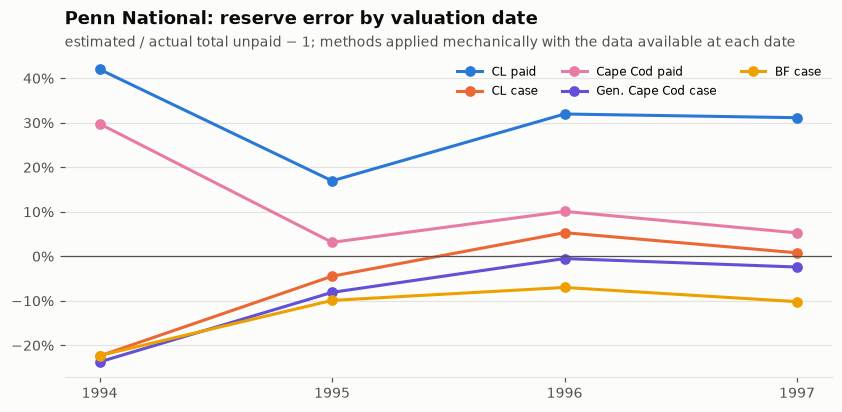

valuation,1994,1995,1996,1997
method,,,,
CL paid,+42.0%,+17.0%,+32.0%,+31.1%
CL case,-22.4%,-4.5%,+5.3%,+0.8%
Cape Cod paid,+29.8%,+3.1%,+10.1%,+5.3%
Gen. Cape Cod case,-23.7%,-8.1%,-0.5%,-2.4%
BF case,-22.3%,-9.9%,-7.0%,-10.2%


In [12]:
rb = B.rolling_backtest(co, rev.ind)
show = ["CL paid", "CL case", "Cape Cod paid", "Gen. Cape Cod case", "BF case"]
piv = rb.pivot(index="valuation", columns="method", values="error_pct")[show]
fig, ax = plt.subplots(figsize=(9, 3.8))
for m in show:
    ax.plot(piv.index, piv[m], marker="o", color=PL.COLOURS[m], label=m)
ax.axhline(0, color=PL.INK_2, lw=0.8)
ax.set_xticks(piv.index)
ax.set_title("Penn National: reserve error by valuation date")
PL.subtitle(ax, "estimated / actual total unpaid − 1; methods applied mechanically with the data available at each date")
PL.pct(ax)
ax.legend(fontsize=8, ncol=3)
PL.save(fig, "08_rolling_backtest")
plt.show()
piv.T.style.format("{:+.1%}")

* **Paid CL over-reserved at every valuation from 1994 to 1997** (by 17-42%). The faster-settlement problem was there throughout, and a company actual-vs-expected review would have flagged it.
* **At the 1994 valuation, all case methods were ~22% short.** With only seven development years, the fitted tail understated the remaining development. Short triangles are where tail judgement matters most.
* From 1995 onward, **case-based methods** were consistently within about ±10%.

## 6. Lessons and what I would do next

**What worked**

* Treating the paid/case disagreement as **the** central question instead of averaging it away.
* Building the BF prior from the **company's own experience with a trend** (Gen. Cape Cod) rather than circularly from CL, or from an industry benchmark the company had drifted away from.
* Letting **back-test evidence across 30 companies** set the method weights, with a single, explained company-specific overlay.

**What I would add in a real review**

1. **Claim counts** for Berquist-Sherman settlement-rate and case-adequacy adjustments.
2. **Reconciliation** of the data to the general ledger and claims system.
3. **Gross vs net** analysis and the reinsurance programme (Schedule P is net only).
4. **Discounting and an explicit risk margin** for an IFRS 17 or Solvency II basis. This dataset is US statutory, undiscounted.
5. **One-year (Merz-Wüthrich) reserve risk** for Solvency II, alongside the ultimate view used here.
6. **Expense reserves** (ULAE), not covered by these data.